# Assignment Report

I analysed the measured signal first using the DFT to identify its frequency components. Three low frequencies, two high frequencies, and an unwanted frequency around 25 Hz were identified. I designed an IIR notch filter by placing two zeros at the unwanted frequency and two poles inside the unit circle. I initially selected a pole radius of 0.95 to create a narrow notch and also to keep the gain at passband frequencies close to 1.

The filtered output was compared with the target signal in both the time and frequency domains. The results showed that the unwanted frequency was strongly suppressed while the useful frequencies were mostly preserved. The RMSE decreased from 1.0284 to 0.5248. I also tested a pole radius of 0.90, but the RMSE increased to 0.5511. Finally, I compared my filter with a Butterworth band-stop filter, which achieved an RMSE of 0.5463. Since the manually designed IIR filter with a pole radius of 0.95 gave the lowest RMSE among the tested designs, I selected it as the final filter.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("7b - Filter Design Assignment DATA.xlsx")
print(df.head())
print()
print(df.columns)

   index   time  signal  Unnamed: 3  Target
0      0  0.000   2.000         NaN   2.000
1      1  0.005   2.904         NaN   2.528
2      2  0.010   4.976         NaN   2.983
3      3  0.015   4.366         NaN   3.201
4      4  0.020   3.454         NaN   3.454

Index(['index', 'time', 'signal', 'Unnamed: 3', 'Target'], dtype='object')


#### First thing to do is to extract the data into numpy arrays:

In [26]:
t = df["time"].to_numpy()
signal = df["signal"].to_numpy()
target = df["Target"].to_numpy()

#### Plotting both target and signal in time domain:

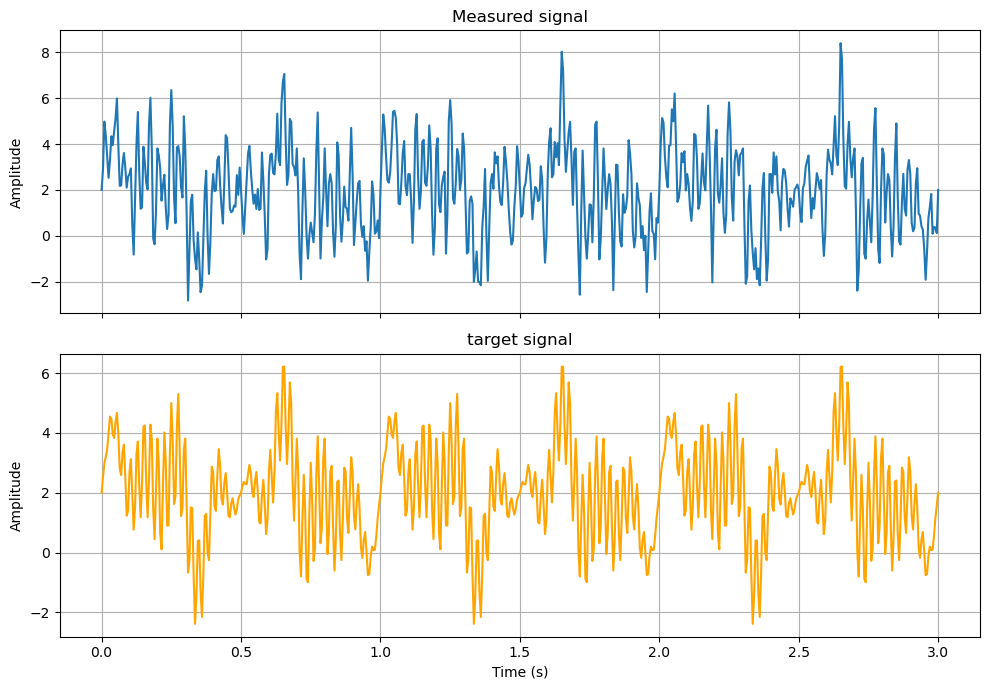

In [27]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex = True)
ax[0].plot(t, signal)
ax[0].set_title("Measured signal")
ax[0].set_ylabel("Amplitude")
ax[0].grid(True)

ax[1].plot(t, target, color="orange")
ax[1].set_title("target signal")
ax[1].set_ylabel("Amplitude")
ax[1].set_xlabel("Time (s)")
ax[1].grid(True)

plt.tight_layout()
plt.show()

#### Calculating the sampling information:

In [28]:
N = len(signal)
dt = t[1] - t[0]
fs = 1 / dt

print("samples:", N)
print("sampling frequency:", fs)

samples: 601
sampling frequency: 200.0


#### Calculating the DFT:

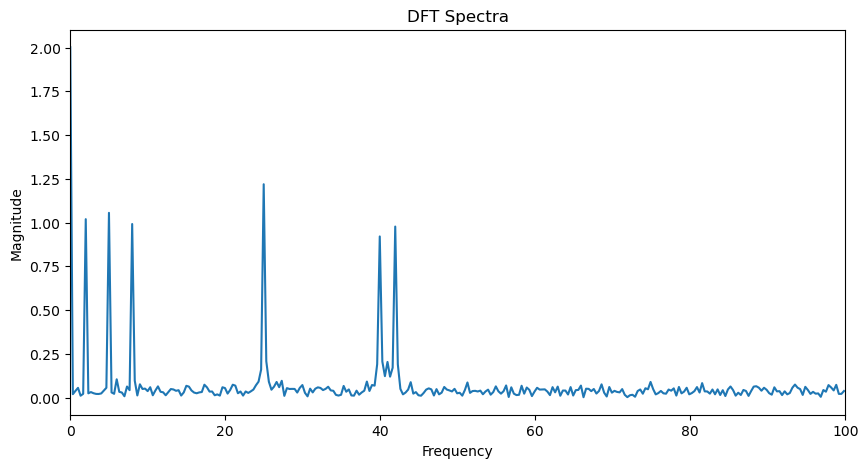

In [29]:
freq = np.fft.rfftfreq(N, d=1/fs)
magnitude = np.abs(np.fft.rfft(signal)) / N
magnitude[1:] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq, magnitude)
plt.xlabel("Frequency")
plt.ylabel("Magnitude")
plt.title("DFT Spectra")
plt.xlim(0, 100)
plt.show()

#### Finding the noise frequency numerically:

In [30]:
mask = (freq >= 15) & (freq <= 35)
selected_frequency = freq[mask]
selected_magnitude = magnitude[mask]

peak_index = np.argmax(selected_magnitude)
noise_freq = selected_frequency[peak_index]
print(f"Noise frequency: {noise_freq:.3f} Hz")

Noise frequency: 24.958 Hz


#### Calculating the digital angular frequency:

In [31]:
w0 = 2 * np.pi * noise_freq / fs

#### Adding zeros to eliminate noise frequency and plotting magnitude response:

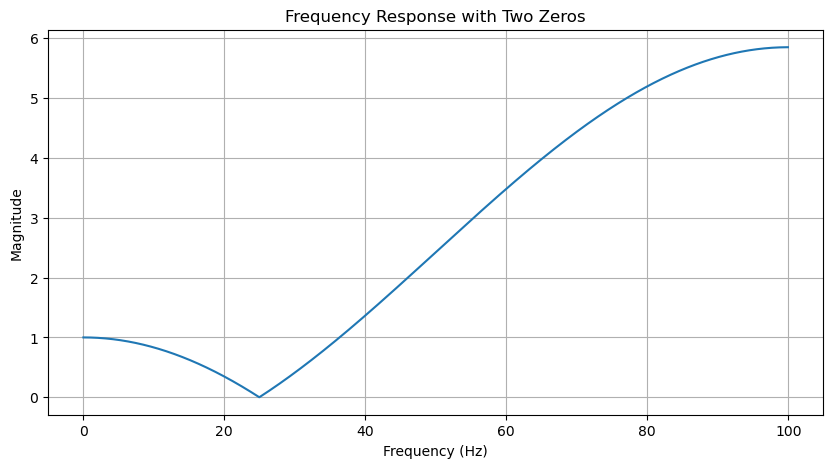

In [32]:
b = np.array([1, -2 * np.cos(w0), 1])
# Normalizing the coefficient
b_fir = b / sum(b)       # FIR: two zeros

from scipy.signal import freqz

f, H = freqz(b_fir, [1], worN=2048, fs=fs)
magnitude_fir = np.abs(H)

plt.figure(figsize=(10, 5))
plt.plot(f, magnitude_fir)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Response with Two Zeros")
plt.grid(True)
plt.show()

At 25 Hz, the magnitude becomes zero, so two zeros successfully reject the unwanted frequency

At 100 Hz, the magnitude is near to 6.0, so high frequencies are strongly amplified

BUT, we want the passband magnitude to be close to 1

#### Adding poles:

I will add two poles at the same angles as the zeros, but slightly inside the unit circle

I start with rho = 0.95 (not smaller), because I want the notch width to be narrower in order to have better gains at passband frequencies

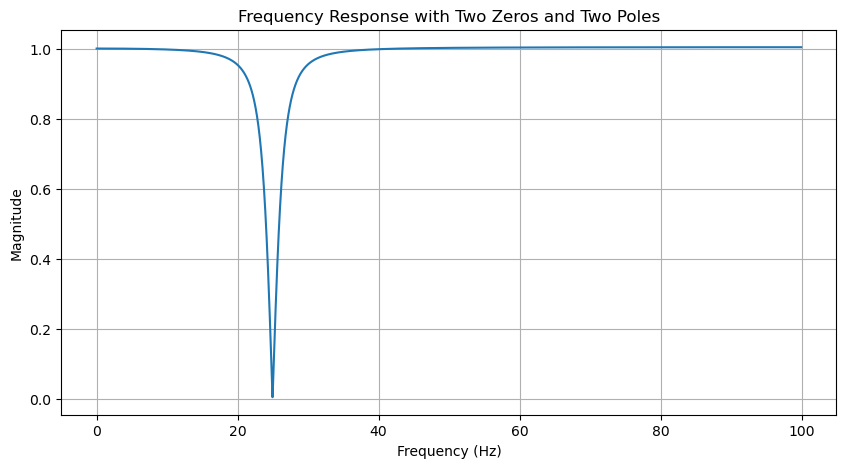

Numerator coefficients = [ 0.95428127 -1.35131998  0.95428127]
Denominator coefficients = [ 1.         -1.34525745  0.9025    ]


In [33]:
rho = 0.95
a = np.array([1, -2 * np.cos(w0) * rho, rho ** 2])
# Normalizing the coefficient
k = sum(a) / sum(b)
b_iir = k * b       # IIR: two zeros and two poles
_, H2 = freqz(b_iir, a, worN=2048, fs=fs)
magnitude_iir = np.abs(H2)

plt.figure(figsize=(10, 5))
plt.plot(f, magnitude_iir)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Response with Two Zeros and Two Poles")
plt.grid(True)
plt.show()
print(f"Numerator coefficients = {b_iir}")
print(f"Denominator coefficients = {a}")


This is much better

    Unwanted 25 Hz frequency is strongly suppressed and the low- and high-frequency components pass with almost no change in amplitude

#### Implementing the difference equation:



The numerator is obtained by multiplying the two zero factors:

$$
B(z)=(1-z_1z^{-1})(1-z_2z^{-1})
$$

$$
B(z)=1-(z_1+z_2)z^{-1}+z_1z_2z^{-2}
$$

Since the zeros are complex conjugates:

$$
B(z)=1-2\cos(\omega_0)z^{-1}+z^{-2}
$$

Similarly, the denominator is obtained by multiplying the two pole factors:

$$
A(z)=(1-p_1z^{-1})(1-p_2z^{-1})
$$

$$
A(z)=1-(p_1+p_2)z^{-1}+p_1p_2z^{-2}
$$

Therefore:

$$
A(z)=1-2\rho\cos(\omega_0)z^{-1}+\rho^2z^{-2}
$$


For the selected pole radius $\rho = 0.95$, the transfer function is:

$$
H(z) = \frac{K(1 - 2\cos(\omega_0)z^{-1} + z^{-2})}
{1 - 2\rho\cos(\omega_0)z^{-1} + \rho^2z^{-2}}
$$

The calculated numerator and denominator coefficients are:

$$
b = [0.954281,\;-1.351320,\;0.954281]
$$

$$
a = [1,\;-1.345257,\;0.902500]
$$

The difference equation is:

$$
y[n] = b_0x[n] + b_1x[n-1] + b_2x[n-2]
- a_1y[n-1] - a_2y[n-2]
$$

Substituting the calculated coefficients:

$$
\begin{aligned}
y[n] ={}& 0.954281x[n] - 1.351320x[n-1] \\
&+ 0.954281x[n-2] + 1.345257y[n-1] \\
&- 0.902500y[n-2]
\end{aligned}
$$


In [41]:
# filtered = lfilter(b_iir, a, signal)
# Using the definition to implement it manually:
filtered = np.zeros(len(signal))
for n in range(len(signal)):
    
    filtered[n] = b_iir[0] * signal[n]
    
    if n >= 1:
        filtered[n] +=  b_iir[1] * signal[n - 1] - a[1] * filtered[n - 1]
    
    if n >= 2:
        filtered[n] += b_iir[2] * signal[n - 2] - a[2] * filtered[n - 2]

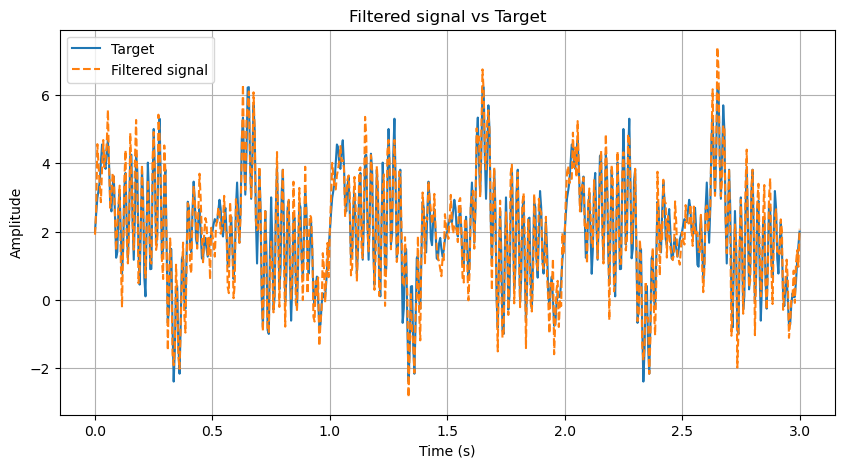

In [42]:
plt.figure(figsize=(10, 5))
plt.plot(t, target, label="Target")
plt.plot(t, filtered, label="Filtered signal", linestyle="--")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Filtered signal vs Target")
plt.legend()
plt.grid(True)
plt.show()

Zooming in to evaluate the difference more clearly:

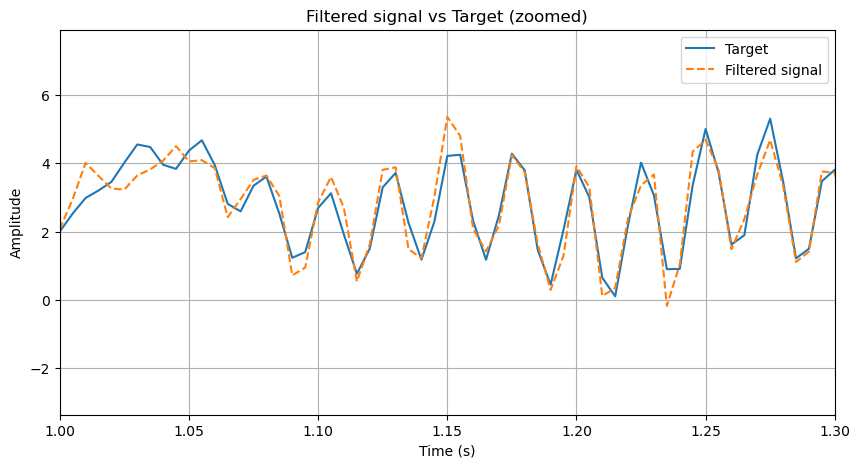

In [43]:
plt.figure(figsize=(10, 5))
plt.plot(t, target, label="Target")
plt.plot(t, filtered, label="Filtered signal", linestyle="--")

plt.xlim(1, 1.3)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Filtered signal vs Target (zoomed)")
plt.legend()
plt.grid(True)
plt.show()

IIR filter is working well, but the filtered signal is not identical to the target

I use RMSE to evaluate how much the filtered signal is close to the target compared with the measured noisy signal. In other words, how much the filter actually improved the signal:

In [44]:
# RMSE before filtering
rmse_before = np.sqrt(np.mean((signal - target) ** 2))
# RMSE after filtering
rmse_after = np.sqrt(np.mean((filtered - target) ** 2))

print(f" RMSE before filtering: {rmse_before:.4f}")
print(f" RMSE after filtering: {rmse_after:.4f}")

 RMSE before filtering: 1.0284
 RMSE after filtering: 0.5248


The filter achieved around 50% RMSE reduction

#### Filtered and original signal spectrum:

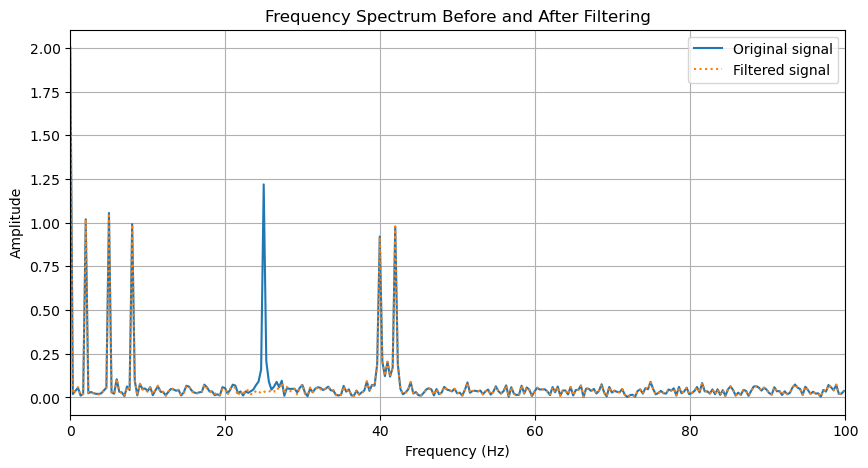

In [49]:
magnitude_filtered = np.abs(np.fft.rfft(filtered)) / N
magnitude_filtered[1:] *= 2
magnitude_signal = np.abs(np.fft.rfft(signal)) / N
magnitude_signal[1:] *= 2

plt.figure(figsize=(10, 5))
plt.plot(freq, magnitude_signal, label="Original signal")
plt.plot(freq, magnitude_filtered, label="Filtered signal", linestyle=":")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Frequency Spectrum Before and After Filtering")
plt.xlim(0, 100)
plt.legend()
plt.grid(True)
plt.show()

Although the 25 Hz peak is strongly suppressed, the filtered output is not identical to the target

The next investigation is the phase shift introduced by the IIR filter

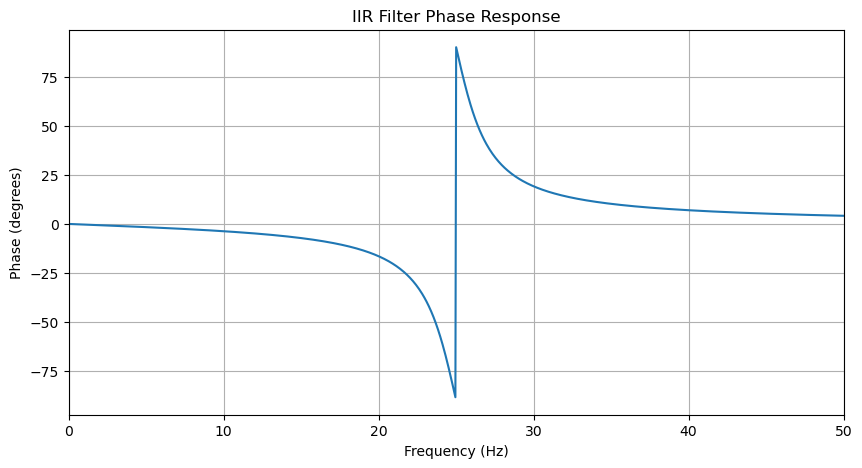

In [51]:
_, H = freqz(b_iir, a, worN=2048, fs=fs)

phase = np.angle(H, deg=True)

plt.figure(figsize=(10, 5))
plt.plot(f, phase)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase (degrees)")
plt.title("IIR Filter Phase Response")
plt.xlim(0, 50)
plt.grid(True)
plt.show()

It is obvious that the IIR filter slightly changes phases of the useful frequencies. (The sudden jump at 25 Hz is because magnitude is zero, so the phase is undefined)

So, this relatively small phase distortion is not necessarily responsible for the RMSE, maybe the remaining error comes from noise that has not completely removed by the IIR filter.

So, I want to test again with another pole radius 

    rho = 0.9 -> this makes the notch width wider

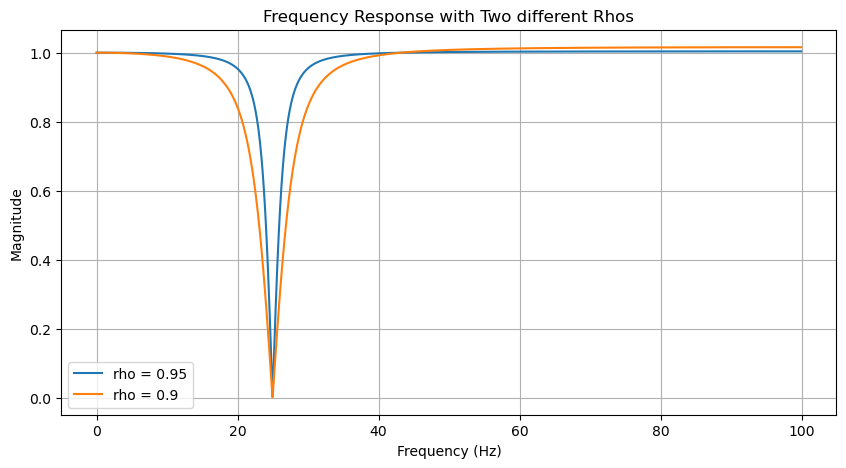

In [53]:
rho = 0.90
a2 = np.array([1, -2 * np.cos(w0) * rho, rho ** 2])
k = sum(a2) / sum(b)
b_iir2 = k * b
_, H3 = freqz(b_iir2, a2, worN=2048, fs=fs)
magnitude_iir2 = np.abs(H3)

plt.figure(figsize=(10, 5))
plt.plot(f, magnitude_iir, label="rho = 0.95")
plt.plot(f, magnitude_iir2, label=f"rho = {rho}")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Response with Two different Rhos")
plt.legend()
plt.grid(True)
plt.show()

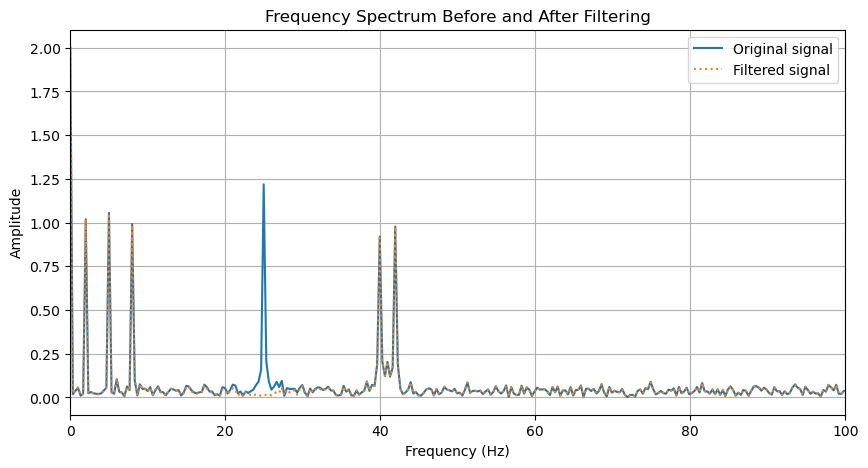

In [54]:
from scipy.signal import lfilter
filtered_iir2 = lfilter(b_iir2, a2, signal)
magnitude_filtered_iir2 = np.abs(np.fft.rfft(filtered_iir2)) / N
magnitude_filtered_iir2[1:] *= 2
magnitude_signal = np.abs(np.fft.rfft(signal)) / N
magnitude_signal[1:] *= 2

plt.figure(figsize=(10, 5))
plt.plot(freq, magnitude_signal, label="Original signal")
plt.plot(freq, magnitude_filtered_iir2, label="Filtered signal", linestyle=":")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Frequency Spectrum Before and After Filtering")
plt.xlim(0, 100)
plt.legend()
plt.grid(True)
plt.show()

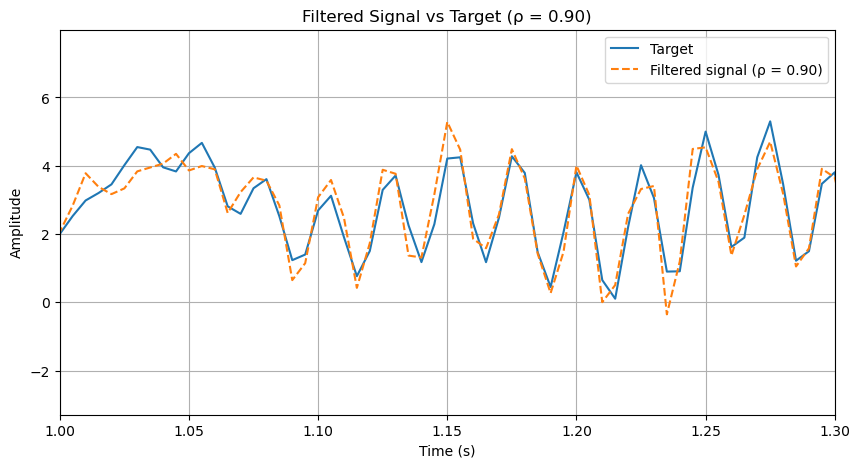

In [57]:
plt.figure(figsize=(10, 5))
plt.plot(t, target, label="Target")
plt.plot(t, filtered_iir2, label="Filtered signal (ρ = 0.90)", linestyle="--")

plt.xlim(1, 1.3)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Filtered Signal vs Target (ρ = 0.90)")
plt.legend()
plt.grid(True)
plt.show()

In [55]:
# RMSE before filtering
rmse_before = np.sqrt(np.mean((signal - target) ** 2))
# RMSE after filtering
rmse_after = np.sqrt(np.mean((filtered_iir2 - target) ** 2))

print(f" RMSE before filtering: {rmse_before:.4f}")
print(f" RMSE after filtering: {rmse_after:.4f}")

 RMSE before filtering: 1.0284
 RMSE after filtering: 0.5511


Decreasing the pole radius made the notch wider, But RMSE increased from 0.5248 to 0.5511 !!!

Therefore, between two rhos I choose rho = 0.95 because it produces better filtering accuracy for this signal

### Comparing the final rho = 0.95 design with a standard butterworth filter

Now, instead of manually placing poles and zeros, I will use scipy.signal.butter()

The manual IIR filter was centered at 25 Hz, for the butterworth filter , I will initially choose a stopband from 23 Hz to 27 Hz

In [1]:
from scipy.signal import butter

In [12]:
b_butter, a_butter = butter(2, [23, 27], btype="bandstop", fs=fs)

# A butterworth band-stop design with prototype order 2 produces a fourth order digital filter
# First manually designed IIR filter is second order
# So, I am comparing two different designs, not two equal order filters

#### plotting the butterworth magnitude response

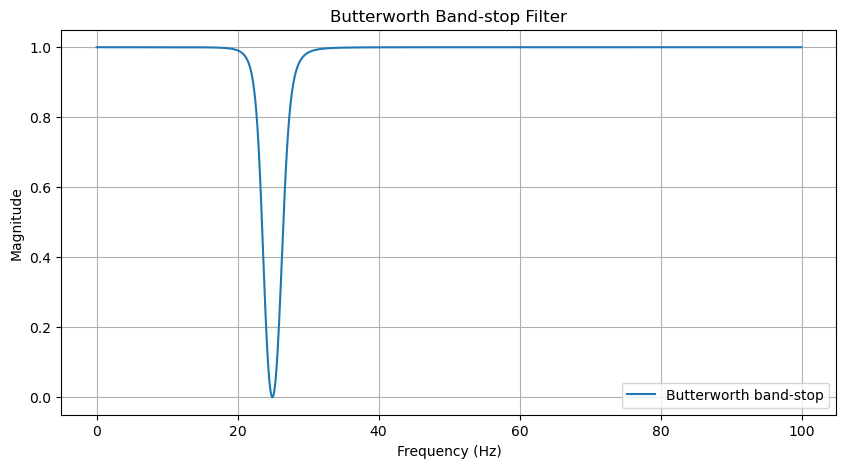

In [13]:
f, H_butter = freqz(b_butter, a_butter, worN=2048, fs=fs)
magnitude_butter = np.abs(H_butter)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude_butter, label = "Butterworth band-stop")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Butterworth Band-stop Filter")
plt.legend()
plt.grid(True)
plt.show()

What can be seen from the graph:

    Around 25 Hz: The magitude drops almost to zero and rejects the nwanted frequency
    Below around 20 Hz: The magnitude stays near to 1, preserving the low-frequency compoents
    Above around 30 Hz: The magnitude again stays close to 1, preserving the high-frequency components

#### Compare butterworth with manual IIR filter 

##### Plotting both magnitude responses:

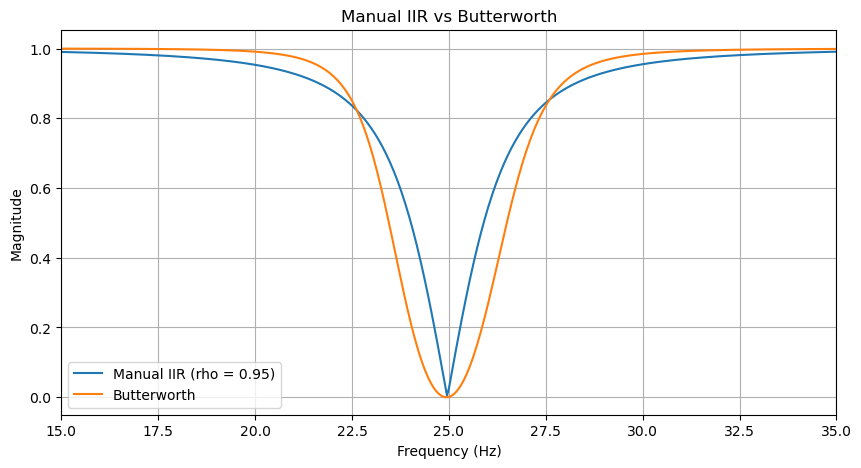

In [17]:
# Producing the selected IIR filter again to prevent any possile faults
rho = 0.95
b = np.array([1, -2 * np.cos(w0), 1])
a_manual = np.array([1, -2 * np.cos(w0) * rho, rho ** 2])
k = sum(a_manual) / sum(b)
b_manual = k * b

f, H_manual = freqz(b_manual, a_manual, worN=2048, fs=fs)
magnitude_manual = np.abs(H_manual)
_, H_butter = freqz(b_butter, a_butter, worN=2048, fs=fs)
magnitude_butter = np.abs(H_butter)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude_manual, label = "Manual IIR (rho = 0.95)")
plt.plot(f, magnitude_butter, label = "Butterworth")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Manual IIR vs Butterworth")
plt.legend()
plt.xlim(15, 35)
plt.grid(True)
plt.show()

Near 25 Hz:

    The butter worth filter attenuates a wider range of frequencies compared with the manual IIR filter

Farther from 25 Hz:

    The butterworth response returns to unity gain more quickly

#### However, this is not enough and I still have to compare filtering accuracy

In [21]:
from scipy.signal import lfilter

filtered_manual = lfilter(b_manual, a_manual, signal)
filtered_butter = lfilter(b_butter, a_butter, signal)

rmse_before = np.sqrt(np.mean((signal - target) ** 2))
rmse_manual = np.sqrt(np.mean((filtered_manual - target) ** 2))
rmse_butter = np.sqrt(np.mean((filtered_butter - target) ** 2))
print(f"RMSE Before Filtering = {rmse_before:.4f}")
print(f"RMSE Manual IIR = {rmse_manual:.4f}")
print(f"RMSE Butterworth = {rmse_butter:.4f}")

RMSE Before Filtering = 1.0284
RMSE Manual IIR = 0.5248
RMSE Butterworth = 0.5463


These values show that interstingly the manual IIR filter performs slightly better than the butterworth filter for this dataset

I think now I can conclude that a filter with seemingly better magnitude response does not necessarily produce a lower RMSE

    Because other features like phase response and filter transients can affect RMSE

##### And the last comparison

#### Plotting both outputs in the time domain

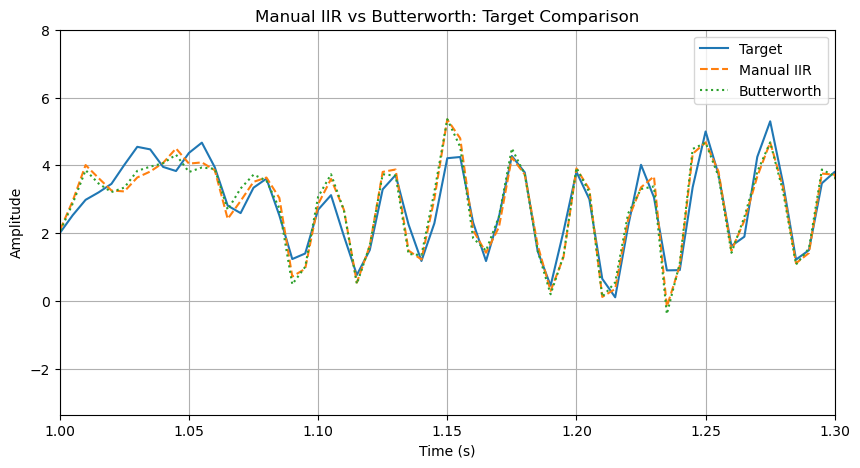

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(t, target, label="Target")
plt.plot(t, filtered_manual, label="Manual IIR", linestyle="--")
plt.plot(t, filtered_butter, label="Butterworth", linestyle=":")

plt.xlim(1, 1.3)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Manual IIR vs Butterworth: Target Comparison")
plt.legend()
plt.grid(True)
plt.show()

Both filters produce very similar outputs, but the manual IIR filter performs slightly better overall. This can also be verified by the RMSE comparison

Therefore, I select the manual IIR filter as the final design